## Question 1

In [2]:
%pip -q install ultralytics huggingface_hub

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from time import perf_counter
from base64 import b64decode
import hashlib
import math
import os
import sys
import zipfile
import requests
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, Javascript, display
from ultralytics import YOLO

OUTPUT_DIR = Path('CV_Lab09_Output')
WEIGHTS_DIR = OUTPUT_DIR / 'weights'
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
COMMON_IMAGE_PATH = OUTPUT_DIR / 'lab_assets.jpg'
IS_COLAB = 'COLAB_RELEASE_TAG' in os.environ or 'google.colab' in sys.modules
CAMERA_INDEX = 0
CAMERA_FRAMES = 15
CONF_THRESHOLD = 0.25
DEVICE = torch.device('cpu')

In [3]:
def camera_frames(camera_index=CAMERA_INDEX, max_frames=CAMERA_FRAMES):
    if IS_COLAB:
        from google.colab.output import eval_js
        display(Javascript("""
        window.lab09Start = async () => {
          const video = document.createElement('video');
          video.setAttribute('playsinline', '');
          video.muted = true;
          video.style.maxWidth = '480px';
          const stream = await navigator.mediaDevices.getUserMedia({video: true, audio: false});
          video.srcObject = stream;
          document.body.appendChild(video);
          await video.play();
          window.lab09Camera = {video, stream};
          return true;
        };
        window.lab09Frame = () => {
          const v = window.lab09Camera.video;
          const canvas = document.createElement('canvas');
          canvas.width = v.videoWidth;
          canvas.height = v.videoHeight;
          canvas.getContext('2d').drawImage(v, 0, 0);
          return canvas.toDataURL('image/jpeg', 0.75);
        };
        window.lab09Stop = () => {
          if (window.lab09Camera) {
            window.lab09Camera.stream.getTracks().forEach(t => t.stop());
            window.lab09Camera.video.remove();
            window.lab09Camera = null;
          }
        };
        """))
        eval_js('lab09Start()')
        try:
            for _ in range(max_frames):
                encoded = eval_js('lab09Frame()')
                frame = cv2.imdecode(np.frombuffer(b64decode(encoded.split(',', 1)[1]), np.uint8), cv2.IMREAD_COLOR)
                if frame is not None:
                    yield frame
        finally:
            eval_js('lab09Stop()')
    else:
        backend = cv2.CAP_DSHOW if os.name == 'nt' else cv2.CAP_ANY
        cap = cv2.VideoCapture(camera_index, backend)
        if not cap.isOpened():
            raise RuntimeError('Webcam unavailable. Check camera permissions and CAMERA_INDEX.')
        cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
        cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)
        try:
            while True:
                ok, frame = cap.read()
                if not ok:
                    break
                yield frame
        finally:
            cap.release()
            cv2.destroyAllWindows()

In [4]:
def show_frame(frame, display_handle=None):
    ok, buffer = cv2.imencode('.jpg', frame)
    if not ok:
        raise ValueError('Could not encode frame')
    image = Image(data=buffer.tobytes())
    if display_handle is None:
        return display(image, display_id=True)
    display_handle.update(image)
    return display_handle

In [5]:
live_model = YOLO('yolo11n.pt')

In [6]:
def detect_lab_assets():
    handle = None
    frame_count = 0
    for frame in camera_frames():
        if frame_count == 0:
            cv2.imwrite(str(COMMON_IMAGE_PATH), frame)
        start = perf_counter()
        result = live_model.predict(frame, conf=0.25, imgsz=640, device='cpu', verbose=False)[0]
        annotated = result.plot()
        fps = 1 / max(perf_counter() - start, 1e-9)
        labels = Counter(result.names[int(v)] for v in result.boxes.cls.cpu().tolist())
        summary = ', '.join(f'{k}: {v}' for k, v in labels.items()) or 'No objects'
        cv2.putText(annotated, f'FPS: {fps:.1f}', (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
        cv2.putText(annotated, summary[:65], (10, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 2)
        if IS_COLAB:
            handle = show_frame(annotated, handle)
        else:
            cv2.imshow('Q1 - YOLO | S: save | Q: quit', annotated)
            key = cv2.waitKey(1) & 0xFF
            if key == ord('s'):
                cv2.imwrite(str(COMMON_IMAGE_PATH), frame)
            if key == ord('q'):
                break
        frame_count += 1
    print(f'Processed: {frame_count} frames | Image: {COMMON_IMAGE_PATH}')

In [ ]:
detect_lab_assets()

## Question 2

In [8]:
from torchvision.models.detection import (
    ssd300_vgg16, SSD300_VGG16_Weights,
    retinanet_resnet50_fpn, RetinaNet_ResNet50_FPN_Weights,
)

COCO80 = (
    'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat',
    'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat',
    'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack',
    'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
    'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket',
    'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple',
    'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake',
    'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop',
    'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink',
    'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush',
)
NAME_TO_ID = {name: i for i, name in enumerate(COCO80)}
ALIASES = {
    'aeroplane': 'airplane', 'motorbike': 'motorcycle', 'sofa': 'couch',
    'pottedplant': 'potted plant', 'diningtable': 'dining table',
    'tvmonitor': 'tv', 'hair dryer': 'hair drier',
}

In [9]:
def download_file(urls, destination, min_bytes=100, sha256=None):
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size >= min_bytes:
        if sha256 is None or hashlib.sha256(destination.read_bytes()).hexdigest() == sha256:
            return destination
    if isinstance(urls, str):
        urls = [urls]
    errors = []
    temp = destination.with_name(destination.name + '.part')
    for url in urls:
        try:
            temp.unlink(missing_ok=True)
            with requests.get(url, stream=True, timeout=(25, 120),
                              headers={'User-Agent': 'Mozilla/5.0'}) as response:
                response.raise_for_status()
                with temp.open('wb') as output:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            output.write(chunk)
            if temp.stat().st_size < min_bytes:
                raise ValueError(f'File too small: {temp.stat().st_size} bytes')
            if sha256 and hashlib.sha256(temp.read_bytes()).hexdigest() != sha256:
                raise ValueError('Checksum mismatch')
            temp.replace(destination)
            return destination
        except (requests.RequestException, OSError, ValueError) as error:
            errors.append(f'{url}: {error}')
            temp.unlink(missing_ok=True)
    raise RuntimeError('All file download sources failed:\n' + '\n'.join(errors))

In [10]:
YOLOV3_CFG = download_file(
    'https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3.cfg',
    WEIGHTS_DIR / 'yolov3.cfg', min_bytes=8000,
)
YOLOV3_NAMES = download_file(
    'https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names',
    WEIGHTS_DIR / 'coco.names', min_bytes=500,
)

In [11]:
YOLOV3_WEIGHTS = download_file([
    'https://huggingface.co/muralee/yolov3_weights/resolve/e2cee1fc5bfbbbc6eee171afd27de8755b43eb9d/yolov3.weights?download=true',
    'https://pjreddie.com/media/files/yolov3.weights',
], WEIGHTS_DIR / 'yolov3.weights', min_bytes=200_000_000,
    sha256='523e4e69e1d015393a1b0a441cef1d9c7659e3eb2d7e15f793f060a21b32f297')

yolo_class_names = YOLOV3_NAMES.read_text(encoding='utf-8').splitlines()
assert len(yolo_class_names) == 80

In [14]:

yolo3_net = cv2.dnn.readNetFromDarknet(
    str(YOLOV3_CFG),
    str(YOLOV3_WEIGHTS)
)

yolo3_net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
yolo3_net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)

yolo3_layers = yolo3_net.getUnconnectedOutLayersNames()

print("YOLOv3 loaded successfully")

YOLOv3 loaded successfully


In [15]:
ssd_weights = SSD300_VGG16_Weights.DEFAULT
retina_weights = RetinaNet_ResNet50_FPN_Weights.DEFAULT
ssd_model = ssd300_vgg16(weights=ssd_weights).to(DEVICE).eval()
retina_model = retinanet_resnet50_fpn(weights=retina_weights).to(DEVICE).eval()
ssd_categories = ssd_weights.meta['categories']
retina_categories = retina_weights.meta['categories']

In [16]:
def normalize_class(name):
    return NAME_TO_ID.get(ALIASES.get(name, name), -1)

In [17]:
def predict_yolov3(frame, threshold=CONF_THRESHOLD):
    h, w = frame.shape[:2]
    blob = cv2.dnn.blobFromImage(frame, 1 / 255.0, (416, 416), swapRB=True, crop=False)
    yolo3_net.setInput(blob)
    outputs = yolo3_net.forward(yolo3_layers)
    boxes, scores, class_ids = [], [], []
    for output in outputs:
        for row in output:
            class_id = int(np.argmax(row[5:]))
            score = float(row[4] * row[5 + class_id])
            if score < threshold:
                continue
            cx, cy, bw, bh = row[:4] * np.array([w, h, w, h])
            x, y = int(cx - bw / 2), int(cy - bh / 2)
            boxes.append([x, y, int(bw), int(bh)])
            scores.append(score)
            class_ids.append(class_id)
    keep = cv2.dnn.NMSBoxes(boxes, scores, threshold, 0.45)
    detections = []
    for i in np.asarray(keep).reshape(-1):
        x, y, bw, bh = boxes[int(i)]
        cls = normalize_class(yolo_class_names[class_ids[int(i)]])
        x1, y1, x2, y2 = max(0, x), max(0, y), min(w, x + bw), min(h, y + bh)
        if cls >= 0 and x2 > x1 and y2 > y1:
            detections.append({'class_id': cls, 'score': scores[int(i)], 'box': [x1, y1, x2, y2]})
    return detections

In [18]:
@torch.inference_mode()
def predict_torchvision(frame, model, categories, threshold=CONF_THRESHOLD):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float().div_(255).to(DEVICE)
    out = model([tensor])[0]
    detections = []
    for box, label, score in zip(out['boxes'], out['labels'], out['scores']):
        score = float(score)
        if score < threshold:
            break
        cls = normalize_class(categories[int(label)])
        if cls >= 0:
            detections.append({'class_id': cls, 'score': score, 'box': box.cpu().tolist()})
    return detections

In [19]:
def predict_ssd(frame, threshold=CONF_THRESHOLD):
    return predict_torchvision(frame, ssd_model, ssd_categories, threshold)

def predict_retinanet(frame, threshold=CONF_THRESHOLD):
    return predict_torchvision(frame, retina_model, retina_categories, threshold)

DETECTORS = {'YOLOv3': predict_yolov3, 'SSD': predict_ssd, 'RetinaNet': predict_retinanet}

In [20]:
def draw_detections(frame, detections):
    result = frame.copy()
    h, w = result.shape[:2]
    for item in detections:
        x1, y1, x2, y2 = [int(v) for v in item['box']]
        x1, x2 = np.clip([x1, x2], 0, w - 1)
        y1, y2 = np.clip([y1, y2], 0, h - 1)
        if x2 <= x1 or y2 <= y1:
            continue
        cv2.rectangle(result, (x1, y1), (x2, y2), (0, 210, 70), 2)
        label = f"{COCO80[item['class_id']]} {item['score']:.2f}"
        cv2.putText(result, label, (x1, max(16, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.52, (0, 210, 70), 2)
    return result

In [21]:
if not COMMON_IMAGE_PATH.exists():
    download_file([
        'https://ultralytics.com/images/bus.jpg',
    ], COMMON_IMAGE_PATH, min_bytes=5_000)

common_frame = cv2.imread(str(COMMON_IMAGE_PATH))
if common_frame is None:
    raise FileNotFoundError(COMMON_IMAGE_PATH)
print(common_frame.shape)

(1080, 810, 3)


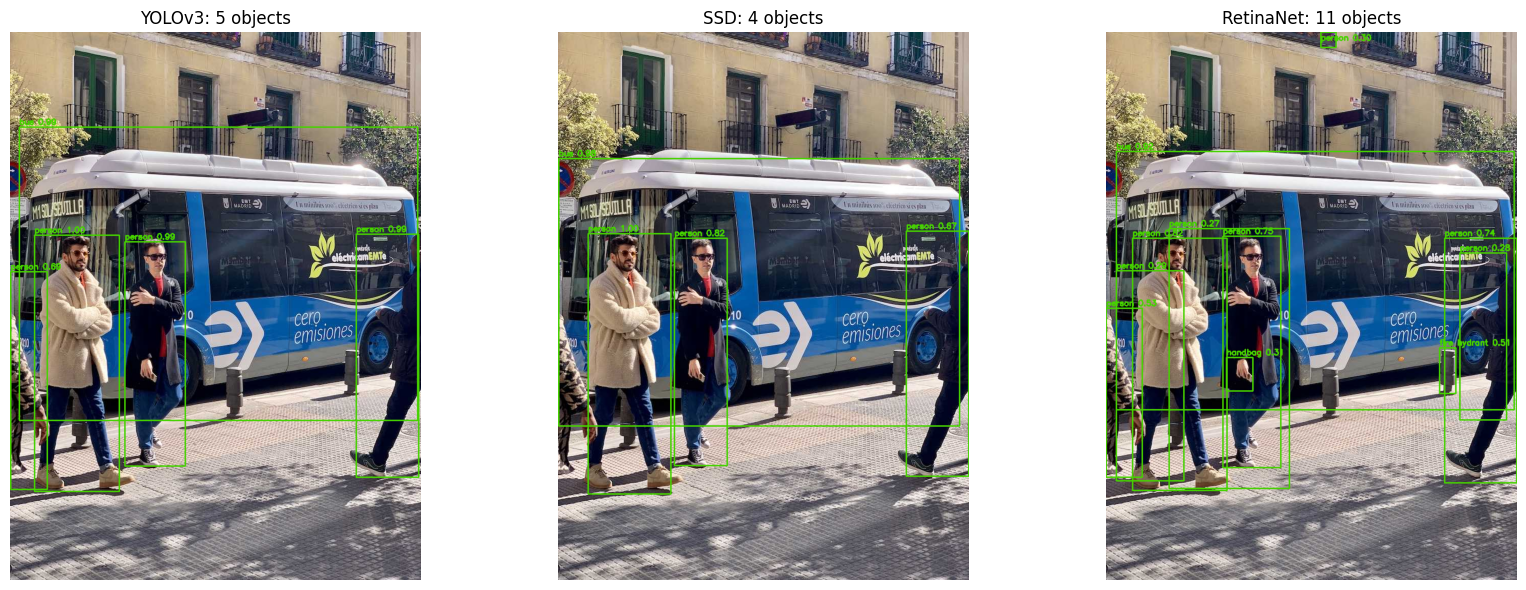

In [22]:
common_predictions = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, (model_name, predict) in zip(axes, DETECTORS.items()):
    detections = predict(common_frame)
    common_predictions[model_name] = detections
    annotated = draw_detections(common_frame, detections)
    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax.set_title(f'{model_name}: {len(detections)} objects')
    ax.axis('off')
    cv2.imwrite(str(OUTPUT_DIR / f'{model_name.lower()}_detections.jpg'), annotated)
plt.tight_layout()
plt.show()

In [23]:
display(pd.DataFrame([
    {'Model': name, 'Object': COCO80[d['class_id']], 'Confidence': round(d['score'], 4)}
    for name, detections in common_predictions.items() for d in detections
]))

,Model,Object,Confidence
0,YOLOv3,person,0.9984
1,YOLOv3,person,0.9939
2,YOLOv3,bus,0.9907
3,YOLOv3,person,0.9905
4,YOLOv3,person,0.6947
5,SSD,person,0.9992
6,SSD,bus,0.9843
7,SSD,person,0.8249
8,SSD,person,0.6718
9,RetinaNet,bus,0.9209


## Question 3

In [24]:
DATA_DIR = OUTPUT_DIR / 'coco128'
ZIP_PATH = OUTPUT_DIR / 'coco128.zip'
if not (DATA_DIR / 'images' / 'train2017').exists():
    download_file([
        'https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip',
        'https://ultralytics.com/assets/coco128.zip',
    ], ZIP_PATH, min_bytes=1_000_000)
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(OUTPUT_DIR)
IMAGE_DIR = DATA_DIR / 'images' / 'train2017'
LABEL_DIR = DATA_DIR / 'labels' / 'train2017'
BENCHMARK_IMAGES = 6
image_paths = sorted(IMAGE_DIR.glob('*.jpg'))[:BENCHMARK_IMAGES]
if not image_paths:
    raise FileNotFoundError(f'No benchmark images in {IMAGE_DIR}')
print(len(image_paths))

6


In [25]:
def load_sample(path, max_side=640):
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f'Invalid image: {path}')
    h, w = image.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    if scale < 1:
        image = cv2.resize(image, (round(w * scale), round(h * scale)))
    h, w = image.shape[:2]
    targets = []
    label_path = LABEL_DIR / f'{path.stem}.txt'
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            fields = line.split()
            if len(fields) != 5:
                continue
            cls, cx, cy, bw, bh = map(float, fields)
            targets.append({'class_id': int(cls), 'box': [
                (cx - bw / 2) * w, (cy - bh / 2) * h,
                (cx + bw / 2) * w, (cy + bh / 2) * h,
            ]})
    return image, targets

In [26]:
def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    return intersection / max(area_a + area_b - intersection, 1e-9)

In [27]:
def update_detection_metrics(metrics, predictions, targets, iou_threshold=0.5):
    classes = {p['class_id'] for p in predictions} | {t['class_id'] for t in targets}
    for cls in classes:
        predictions_cls = sorted((p for p in predictions if p['class_id'] == cls),
                                 key=lambda p: p['score'], reverse=True)
        targets_cls = [t for t in targets if t['class_id'] == cls]
        used = set()
        metrics[cls]['predictions'] += len(predictions_cls)
        metrics[cls]['confidence_sum'] += sum(p['score'] for p in predictions_cls)
        metrics[cls]['small_total'] += sum(
            (t['box'][2] - t['box'][0]) * (t['box'][3] - t['box'][1]) < 32 ** 2
            for t in targets_cls
        )
        for p in predictions_cls:
            candidates = [(box_iou(p['box'], t['box']), i)
                          for i, t in enumerate(targets_cls) if i not in used]
            best_iou, i = max(candidates, default=(0, -1))
            if best_iou >= iou_threshold:
                used.add(i)
                metrics[cls]['tp'] += 1
                box = targets_cls[i]['box']
                if (box[2] - box[0]) * (box[3] - box[1]) < 32 ** 2:
                    metrics[cls]['small_tp'] += 1
            else:
                metrics[cls]['fp'] += 1
        metrics[cls]['fn'] += len(targets_cls) - len(used)

In [28]:
def score_metrics(metrics):
    tp = sum(row['tp'] for row in metrics.values())
    fp = sum(row['fp'] for row in metrics.values())
    fn = sum(row['fn'] for row in metrics.values())
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    small_total = sum(row['small_total'] for row in metrics.values())
    small_tp = sum(row['small_tp'] for row in metrics.values())
    detected = sum(row['predictions'] for row in metrics.values())
    mean_conf = sum(row['confidence_sum'] for row in metrics.values()) / max(detected, 1)
    return precision, recall, f1, mean_conf, small_tp, small_total

In [29]:
summary_rows, per_class_rows = [], []
for model_name, predict in DETECTORS.items():
    metrics = defaultdict(lambda: defaultdict(float))
    times = []
    predict(load_sample(image_paths[0])[0])
    for path in image_paths:
        frame, targets = load_sample(path)
        start = perf_counter()
        predictions = predict(frame)
        times.append(perf_counter() - start)
        update_detection_metrics(metrics, predictions, targets)
    precision, recall, f1, mean_conf, small_tp, small_total = score_metrics(metrics)
    latency = float(np.mean(times))
    summary_rows.append({
        'Model': model_name, 'Images': len(image_paths), 'FPS': 1 / latency,
        'Time per frame (ms)': latency * 1000, 'Precision@0.5': precision,
        'Recall@0.5': recall, 'F1@0.5': f1, 'Mean confidence': mean_conf,
        'Small-object recall': small_tp / small_total if small_total else np.nan,
        'Small objects': int(small_total),
    })
    for cls, row in metrics.items():
        tp, fp, fn = row['tp'], row['fp'], row['fn']
        per_class_rows.append({
            'Model': model_name, 'Class': COCO80[cls], 'Ground truth': int(tp + fn),
            'Precision': tp / max(tp + fp, 1), 'Recall': tp / max(tp + fn, 1),
            'Mean confidence': row['confidence_sum'] / max(row['predictions'], 1),
        })

In [30]:
summary_df = pd.DataFrame(summary_rows).sort_values('FPS', ascending=False).reset_index(drop=True)
per_class_df = pd.DataFrame(per_class_rows).sort_values(['Class', 'Model']).reset_index(drop=True)
display(summary_df.round(3))
display(per_class_df.round(3))
summary_df.to_csv(OUTPUT_DIR / 'comparison_summary.csv', index=False)
per_class_df.to_csv(OUTPUT_DIR / 'per_class_metrics.csv', index=False)

,Model,Images,FPS,Time per frame (ms),Precision@0.5,Recall@0.5,F1@0.5,Mean confidence,Small-object recall,Small objects
0,YOLOv3,6,1.459,685.216,0.857,0.750,0.800,0.749,NaN,0
1,SSD,6,0.879,1137.780,0.786,0.688,0.733,0.692,NaN,0
2,RetinaNet,6,0.159,6289.547,0.485,1.000,0.653,0.530,NaN,0


,Model,Class,Ground truth,Precision,Recall,Mean confidence
0,RetinaNet,banana,0,0.000,0.000,0.267
1,RetinaNet,bird,0,0.000,0.000,0.256
2,RetinaNet,boat,0,0.000,0.000,0.272
3,RetinaNet,bowl,3,0.429,1.000,0.437
4,SSD,bowl,3,0.500,0.667,0.561
5,YOLOv3,bowl,3,1.000,1.000,0.712
6,RetinaNet,broccoli,1,1.000,1.000,0.847
7,SSD,broccoli,1,1.000,1.000,0.785
8,YOLOv3,broccoli,1,0.000,0.000,0.000
9,RetinaNet,cake,0,0.000,0.000,0.277


## Question 4

In [31]:
fastest = summary_df.loc[summary_df['FPS'].idxmax()]
print(f"Real-time detection: {fastest['Model']} ({fastest['FPS']:.2f} FPS, "
      f"{fastest['Time per frame (ms)']:.1f} ms/frame on CPU).")

Real-time detection: YOLOv3 (1.46 FPS, 685.2 ms/frame on CPU).


In [32]:
small = summary_df.dropna(subset=['Small-object recall'])
if len(small):
    best_small = small.loc[small['Small-object recall'].idxmax()]
    print(f"Small objects: {best_small['Model']} "
          f"(recall {best_small['Small-object recall']:.3f}, "
          f"N={int(best_small['Small objects'])}).")
else:
    print('Small objects: no small ground-truth objects in sampled images.')

Small objects: no small ground-truth objects in sampled images.


In [33]:
model_sizes = {
    'YOLOv3': YOLOV3_WEIGHTS.stat().st_size / (1024 ** 2),
    'SSD': sum(p.numel() * p.element_size() for p in ssd_model.state_dict().values()) / (1024 ** 2),
    'RetinaNet': sum(p.numel() * p.element_size() for p in retina_model.state_dict().values()) / (1024 ** 2),
}
display(pd.DataFrame([{'Model': name, 'Weights (MiB)': size}
                      for name, size in model_sizes.items()]).round(1))
print(f"CPU-only: {fastest['Model']} had the lowest observed inference latency. "
      'Consider RAM and model size too.')
print('Precision/recall: confidence >= 0.25, IoU >= 0.50; COCO128 is a training subset, not a holdout test.')

,Model,Weights (MiB)
0,YOLOv3,236.5
1,SSD,136.0
2,RetinaNet,130.2


CPU-only: YOLOv3 had the lowest observed inference latency. Consider RAM and model size too.
Precision/recall: confidence >= 0.25, IoU >= 0.50; COCO128 is a training subset, not a holdout test.


## Question 5

In [34]:
pose_model = YOLO('yolo11n-pose.pt')

In [35]:
KEYPOINT_NAMES = [
    'nose', 'left_eye', 'right_eye', 'left_ear', 'right_ear',
    'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow',
    'left_wrist', 'right_wrist', 'left_hip', 'right_hip',
    'left_knee', 'right_knee', 'left_ankle', 'right_ankle',
]
SKELETON = [
    (5, 6), (5, 7), (7, 9), (6, 8), (8, 10), (5, 11), (6, 12),
    (11, 12), (11, 13), (13, 15), (12, 14), (14, 16),
    (0, 1), (0, 2), (1, 3), (2, 4), (3, 5), (4, 6),
]

In [36]:
def joint_angle(a, b, c):
    v1 = np.asarray(a) - np.asarray(b)
    v2 = np.asarray(c) - np.asarray(b)
    cosine = np.dot(v1, v2) / max(np.linalg.norm(v1) * np.linalg.norm(v2), 1e-9)
    return math.degrees(math.acos(float(np.clip(cosine, -1, 1))))

In [37]:
def draw_pose(frame, result):
    image = frame.copy()
    panel = np.zeros((frame.shape[0], 300, 3), dtype=np.uint8)
    keypoints = result.keypoints
    xy = keypoints.xy.cpu().numpy() if keypoints is not None else np.empty((0, 17, 2))
    conf = (keypoints.conf.cpu().numpy() if keypoints is not None and keypoints.conf is not None
            else np.ones(xy.shape[:2]))
    for person_id, joints in enumerate(xy):
        valid = (conf[person_id] > 0.35) & (joints[:, 0] > 0) & (joints[:, 1] > 0)
        for a, b in SKELETON:
            if valid[a] and valid[b]:
                cv2.line(image, tuple(joints[a].astype(int)), tuple(joints[b].astype(int)), (0, 255, 0), 2)
        for index, (x, y) in enumerate(joints):
            if valid[index]:
                cv2.circle(image, (int(x), int(y)), 4, (0, 190, 255), -1)
        if person_id == 0:
            cv2.putText(panel, 'Live joint coordinates', (8, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)
            for i, name in enumerate(KEYPOINT_NAMES):
                value = f'({joints[i, 0]:.0f}, {joints[i, 1]:.0f})' if valid[i] else '--'
                cv2.putText(panel, f'{name}: {value}', (8, 49 + i * 21),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.38, (180, 255, 180), 1)
            if all(valid[i] for i in (5, 7, 9)):
                angle = joint_angle(joints[5], joints[7], joints[9])
                cv2.putText(image, f'Left elbow: {angle:.1f} deg', (10, 65),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
    return np.hstack([image, panel]), len(xy)

In [38]:
def run_pose_estimation():
    handle = None
    frame_count = 0
    for frame in camera_frames():
        start = perf_counter()
        result = pose_model.predict(frame, imgsz=640, conf=0.25, device='cpu', verbose=False)[0]
        annotated, people = draw_pose(frame, result)
        fps = 1 / max(perf_counter() - start, 1e-9)
        cv2.putText(annotated, f'People: {people} | FPS: {fps:.1f}', (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.64, (0, 255, 255), 2)
        if IS_COLAB:
            handle = show_frame(annotated, handle)
            cv2.imwrite(str(OUTPUT_DIR / 'pose_estimation.jpg'), annotated)
        else:
            cv2.imshow('Q5 - Pose | S: save | Q: quit', annotated)
            key = cv2.waitKey(1) & 0xFF
            if key == ord('s'):
                cv2.imwrite(str(OUTPUT_DIR / 'pose_estimation.jpg'), annotated)
            if key == ord('q'):
                break
        frame_count += 1
    print(f'Processed: {frame_count} frames')

In [ ]:
run_pose_estimation()